# 02 · Where are the stations?

**Who Gets a Bluebike?** · CP 101 final project

Plot the cleaned Bluebikes stations on a map of Boston. The city is the census tracts in `data/clean/boston_tracts.geojson`. Station points come from `data/clean/stations.csv`.

Run `01_clean_data.ipynb` first so those files exist.

Matplotlib is building the font cache; this may take a moment.


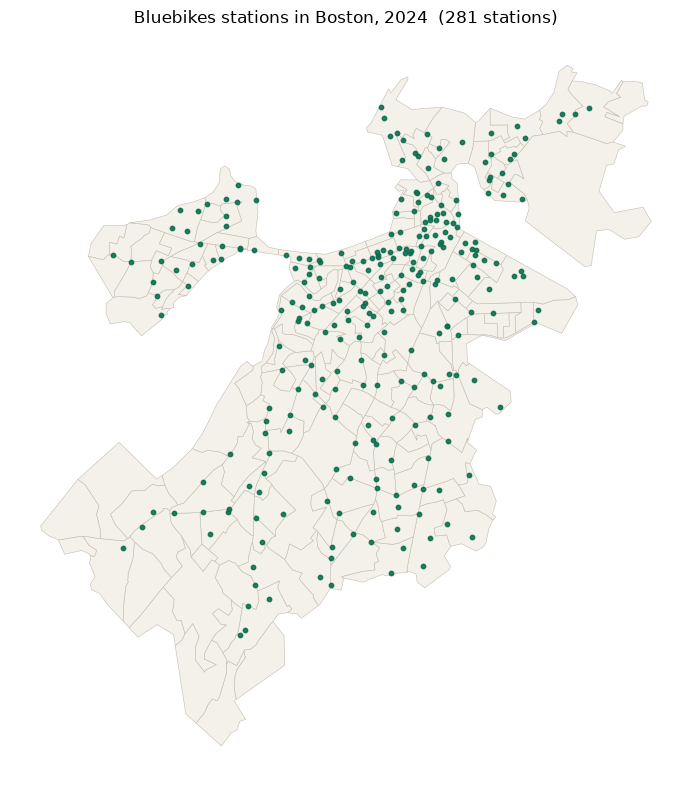

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

CLEAN = Path("../data/clean")
LOCAL_CRS = 2249  # NAD83 / Massachusetts Mainland, in feet

tracts = gpd.read_file(CLEAN / "boston_tracts.geojson").to_crs(LOCAL_CRS)
stations = pd.read_csv(CLEAN / "stations.csv")

# lat/lon are degrees (EPSG:4326). Keep stations inside Boston so they sit on this map.
boston_stations = stations[stations["in_boston"]].copy()
stations_gdf = gpd.GeoDataFrame(
    boston_stations,
    geometry=gpd.points_from_xy(boston_stations["lon"], boston_stations["lat"]),
    crs=4326,
).to_crs(LOCAL_CRS)

fig, ax = plt.subplots(figsize=(8, 8))
tracts.plot(ax=ax, color="#f4f1ea", edgecolor="#c4bdb2", linewidth=0.4)
stations_gdf.plot(ax=ax, color="#0b6e4f", markersize=10, alpha=0.9)
ax.set_title(f"Bluebikes stations in Boston, 2024  ({len(stations_gdf)} stations)")
ax.set_axis_off()
plt.tight_layout()
plt.show()

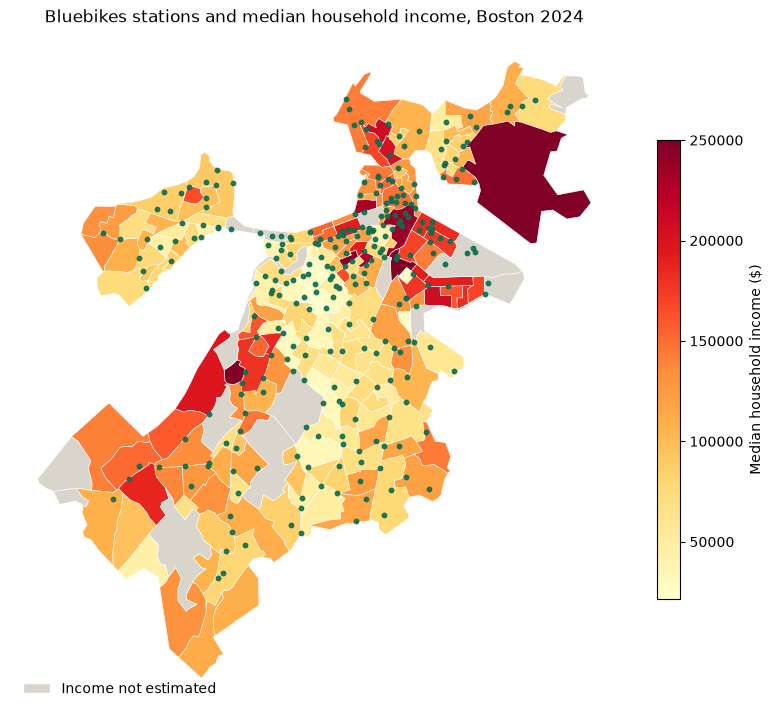

In [2]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(8, 8))
tracts.plot(
    ax=ax,
    column="median_hh_income",
    cmap="YlOrRd",
    legend=True,
    legend_kwds={"label": "Median household income ($)", "shrink": 0.6},
    missing_kwds={"color": "#d9d4cc"},
    edgecolor="white",
    linewidth=0.4,
)
stations_gdf.plot(ax=ax, color="#0b6e4f", markersize=10, alpha=0.9)
ax.legend(
    handles=[Patch(facecolor="#d9d4cc", edgecolor="white", label="Income not estimated")],
    loc="lower left",
    frameon=False,
)
ax.set_title("Bluebikes stations and median household income, Boston 2024")
ax.set_axis_off()
plt.tight_layout()
plt.show()

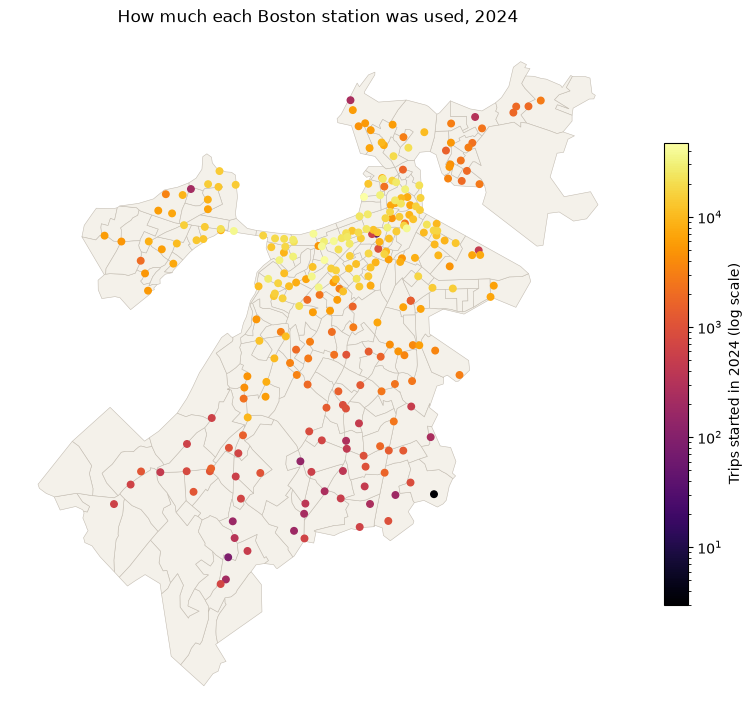

In [3]:
from matplotlib.colors import LogNorm

# Every month of 2024, summed. The project counts a trip at the station where it started.
usage = (
    pd.read_csv(CLEAN / "station_month.csv")
    .groupby("station_id", as_index=False)["trips_started"]
    .sum()
)
usage_gdf = stations_gdf.merge(usage, on="station_id").sort_values("trips_started")

fig, ax = plt.subplots(figsize=(8, 8))
tracts.plot(ax=ax, color="#f4f1ea", edgecolor="#c4bdb2", linewidth=0.4)
usage_gdf.plot(
    ax=ax,
    column="trips_started",
    cmap="inferno",
    norm=LogNorm(vmin=usage_gdf["trips_started"].min(), vmax=usage_gdf["trips_started"].max()),
    markersize=22,
    legend=True,
    legend_kwds={"label": "Trips started in 2024 (log scale)", "shrink": 0.6},
)
ax.set_title("How much each Boston station was used, 2024")
ax.set_axis_off()
plt.tight_layout()
plt.show()